# Stage 1, rehearsed on the virtual NEOARM

This notebook runs the same scripts as the real session: `stage1_acquire.py` drives the microscope
through PyJEM, and `stage1_analysis.py` turns the frames into a model that predicts where the beam
lands for any lens setting and any beam shift or tilt.

On the real microscope, the first code cell is just `from PyJEM import TEM3, detector`.
The virtual one differs in three ways: its lens values are not the NEOARM's, its lenses settle
instantly (`settle_s=0` here, about 2 s for real), and its camera image is mirrored, which the
analysis has to find by itself.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"
import shutil
from pathlib import Path

import projector_figures as F
import stage1_acquire as S
import stage1_analysis as A
from temgym_core.virtual.pyjem import facade
from virtual_neoarm import REFERENCE_SPOT, build_virtual_neoarm

F.apply_style()
OUT = Path("../generated/stage1_virtual")
shutil.rmtree(OUT, ignore_errors=True)
scope, _, _ = build_virtual_neoarm(ray_sample_power=17, detector_samples_per_pixel=8)
TEM3, detector = facade(scope)

## 1. Set up

At the console: 200 kV, MAG, the 40k row, spot size, condenser aperture, camera binning and
exposure. Specimen out.

In [2]:
TEM3.HT3().SetHtValue(200e3)
eos = TEM3.EOS3()
eos.SelectFunctionMode(0)
S.select_magnification(eos, 40000.0)
eos.SelectSpotSize(REFERENCE_SPOT)
aperture = TEM3.Apt3(); aperture.SelectKind(1); aperture.SetSize(1)
camera = detector.Detector(detector.get_attached_detector()[0])
camera.set_detectorsetting({"BinningSize": 8, "ExposureTimeValue": 0.01e6})

{'ImagingArea': {'X': 0, 'Y': 0, 'Width': 256, 'Height': 256},
 'BinningSize': 8,
 'ExposureTimeValue': 10000.0,
 'GainIndex': 0,
 'OffsetIndex': 0,
 'frameIntegration': 1,
 'scanMode': 0,
 'OutputImageInformation': {'DataBits': 32,
  'ImageSize': 262144,
  'PixelsPerMeter': 9090.90909090909}}

## 2. Read the 40k row and the diffraction setting

One call reads every lens in MAG, switches to DIFF at 80 cm (where the gold rings fit on the
camera), reads every lens again, and goes back to MAG. Only IL1–IL3 and PL1 should differ.

In [3]:
base, diffraction, changed = S.read_diffraction_setting(TEM3, camera_length_cm=80)
F.table(["lens", "MAG (40k row)", "DIFF (80 cm)"], [[k, *v] for k, v in changed.items()])

DIFF at 80cm


| lens | MAG (40k row) | DIFF (80 cm) |
|---|---|---|
| IL1 | 46458 | 26495 |
| IL2 | 46445 | 33825 |
| IL3 | 39733 | 54328 |

## 3. Are CLA1 and CLA2 pure shift and pure tilt?

In focus (40k row) a pure tilt does not move the spot; at the diffraction setting a pure shift
does not.

In [4]:
test = S.deflector_test(TEM3, detector, OUT / "deflector_test", base, diffraction, units=10000, settle_s=0)
F.table(["setting", "shift (CLA1) moves the beam", "tilt (CLA2) moves the beam"],
        [[k, f"{v['CLA1 (shift)']:.3f} px", f"{v['CLA2 (tilt)']:.3f} px"] for k, v in test.items()])

first frame: 256x256, read as <i4, values -7 to 4711 (if these look wrong, pass dtype='<u2' or similar)


| setting | shift (CLA1) moves the beam | tilt (CLA2) moves the beam |
|---|---|---|
| in focus | 36.292 px | 0.010 px |
| diffraction | 0.000 px | 14.540 px |

## 4. Stage 1

12 visits: the 8 lens settings, the diffraction setting, setting 0 twice more (to see how much the
beam wobbles) and once with y kicks. At each, a ± shift and a ± tilt of about 50 px.

settings [5, 6, 7]: a factor above the DAC range was replaced by its reciprocal


first frame: 256x256, read as <i4, values -6 to 16 (if these look wrong, pass dtype='<u2' or similar)


visit 1/12 (setting 0, x kicks) done


visit 2/12 (setting 1, x kicks) done


visit 3/12 (setting 2, x kicks) done


visit 4/12 (setting 3, x kicks) done


... (4 outputs left out)

visit 9/12 (setting 7, x kicks) done


visit 10/12 (setting diffraction, x kicks) done


visit 11/12 (setting 0, x kicks) done


visit 12/12 (setting 0, y kicks) done


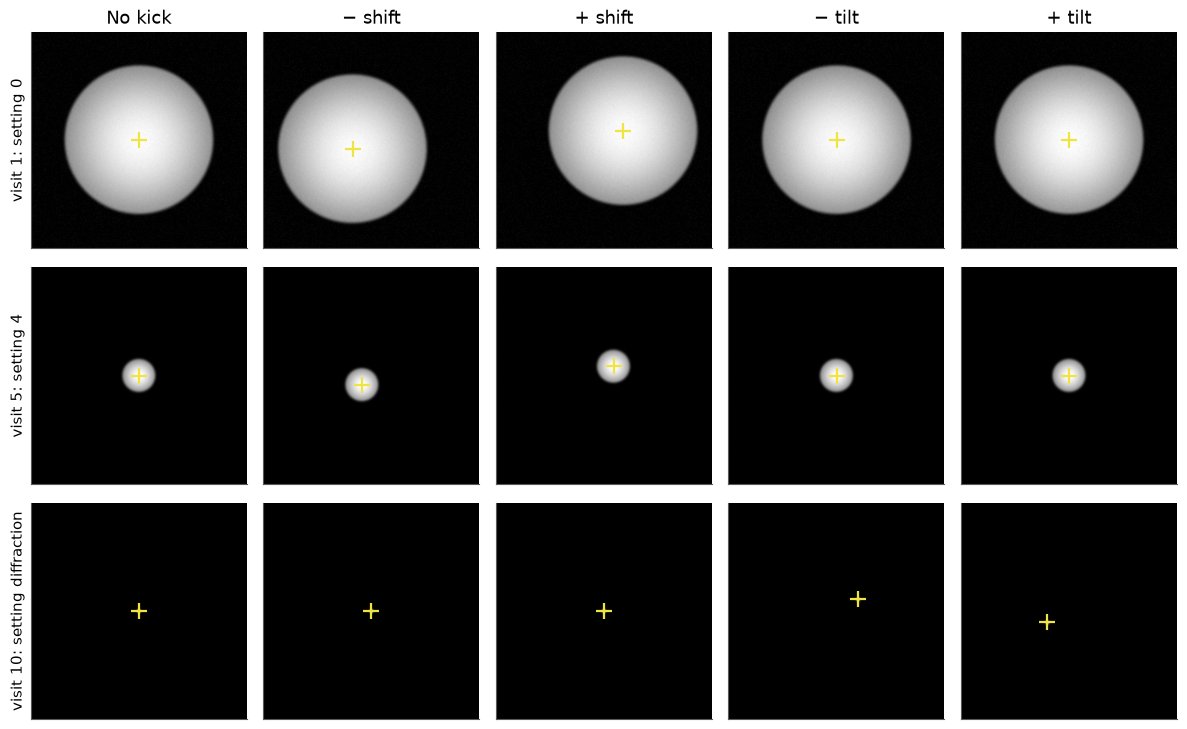

In [5]:
folder = S.run(TEM3, detector, OUT / "stage1", diffraction=diffraction, settle_s=0, max_units=(20000, 20000))
F.session_frames(folder, visits=(0, 4, 9))

## 5. The model

The fit tries both camera handednesses and pure or mixed deflectors, and keeps the simplest that
fits to the wobble. χ²/dof near 1 means it does; far above 1, the worst-fitting measurements say
which visits to look at.

In [6]:
model = A.fit_session(folder)
F.table(["", "result"], A.summary(model))

|  | result |
|---|---|
| camera image mirrored | True |
| deflector y axis flipped | False |
| deflectors | pure |
| beam-position wobble (from the repeats) | 0.005 px |
| χ²/dof (≈ 1: fits to the wobble) | 0.61 |
| worst-fitting measurements | visit 8 (6) tilt: 0.006 px; visit 6 (0) shift: 0.005 px; visit 2 (1) tilt: 0.005 px |

## 6. Does it predict lens settings it never saw?

Eight new settings, each a blend of three measured ones. The model predicts each beam move
before it is measured.

first frame: 256x256, read as <i4, values -7 to 15 (if these look wrong, pass dtype='<u2' or similar)


  dropped (beam cut by the frame edge): visit 2 shift


largest error: 0.006 px over 15 beam moves


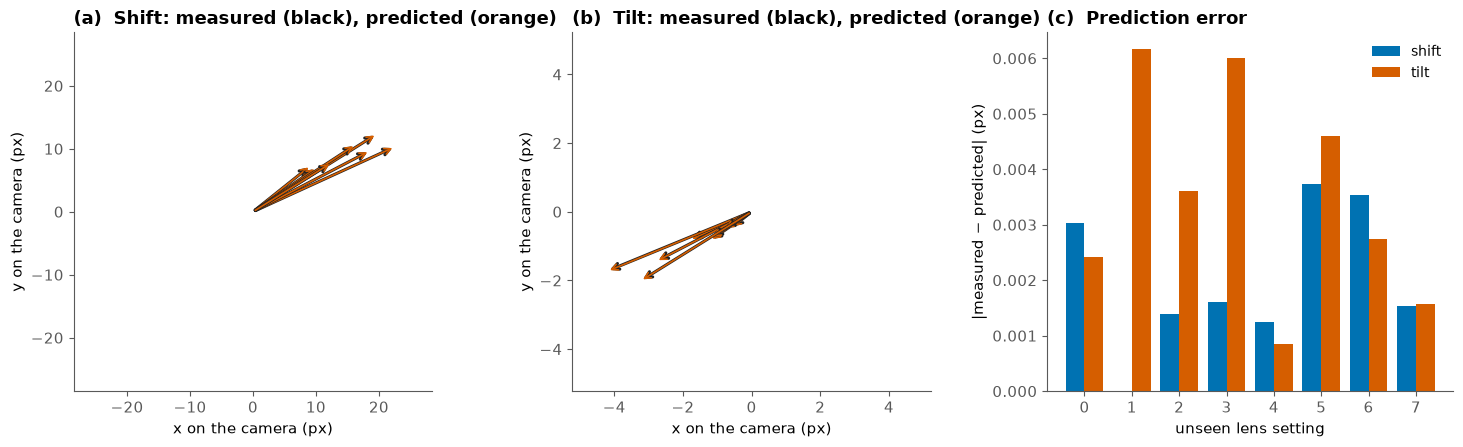

In [7]:
check = S.check_run(TEM3, detector, OUT / "check", A.unseen_settings(folder), offsets=(10000, 10000), settle_s=0)
rows = A.compare(model, check)
print(f"largest error: {max(r['error'] for r in rows):.3f} px over {len(rows)} beam moves")
F.prediction_check_figure(rows)

## 7. If there is time: the anchors

They turn the model's deflector units into metres and radians. With the specimen in:
- **the cross grating at the 40k row**, the beam spread (CL3 weaker) so the squares fill the
  frame: the lattice of squares gives the magnification |A|;
- **gold at the diffraction setting**, beam condensed: the ring radii give the camera length |B|.

The virtual specimens are TemGym too: the grating weights the rays by its transmission; every lit
gold grain sends a Gaussian beamlet at its Bragg angle.

| anchor | measured | hidden truth | error |
|---|---|---|---|
| magnification |A| (40k row) | 40036 | 39998 | +0.09% |
| camera length |B| (diffraction) | 0.7999 m | 0.7999 m | +0.01% |

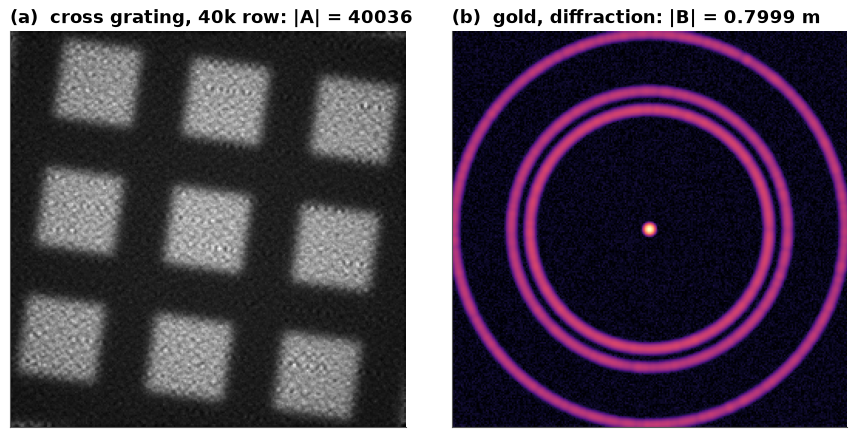

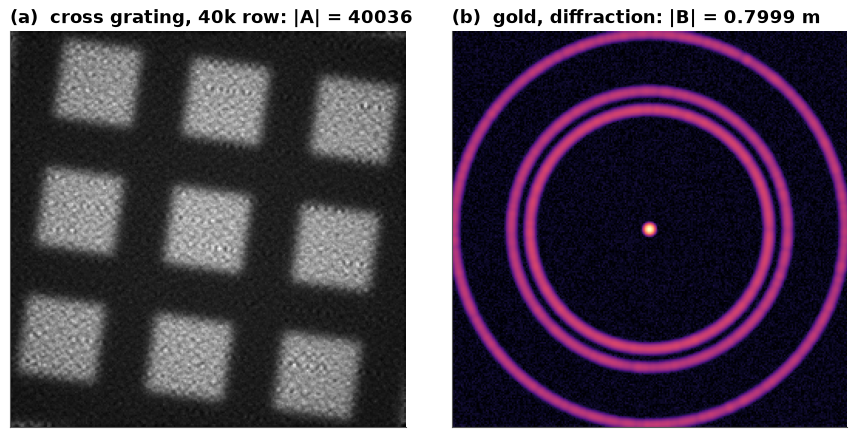

In [8]:
from temgym_core.virtual import CrossGrating, PolycrystallineGold
from virtual_neoarm import true_magnification_and_camera_length as truth

scope.specimen = CrossGrating(period=230e-9)             # at the microscope: the grid, at a grating area
LENS = TEM3.Lens3()
LENS.SetFLCSw(2, 1); LENS.SetFLCAbs(2, int(0.7 * LENS.GetCL3()))   # spread the beam (CL3)
grating = S.take_frame(detector, OUT / "anchors", "grating")
true_a = truth(scope)[0]
LENS.SetFLCSw(2, 0)                                      # condensed again

scope.specimen = PolycrystallineGold()                   # at the microscope: move to a gold area
S.select_camera_length(eos, 80)
gold = S.take_frame(detector, OUT / "anchors", "gold")
true_b = truth(scope)[1]
eos.SelectFunctionMode(0)

result = A.anchors(grating, gold, period_m=230e-9, pitch_m=110e-6, ht_v=200e3)
F.table(["anchor", "measured", "hidden truth", "error"],
        [["magnification |A| (40k row)", f"{result['magnification']:.0f}", f"{true_a:.0f}", f"{result['magnification'] / true_a - 1:+.2%}"],
         ["camera length |B| (diffraction)", f"{result['camera_length_m']:.4f} m", f"{true_b:.4f} m", f"{result['camera_length_m'] / true_b - 1:+.2%}"]])
F.anchor_frames(grating, gold, result)

## Bring back from the real session

The stage-1 folder, the lens readout from step 2, the deflector test, and if there was time a
`check_run` folder and the two anchor frames (with the grating's certified period). Then `A.fit_session(folder)` and `A.compare(model, check_folder)`.